# Digital Image Processing — Lab Task #05
## Spatial Filtering and Convolution

**Student Name:** Zoya Mazhar 
**Roll Number:** 2024-SE-26
**Department:** Software Engineering  
**University:** The University of Azad Jammu and Kashmir  
**Lab:** Digital Image Processing  
**Lab Task:** 05 — Spatial Filtering and Convolution

> Before submission, replace the roll-number placeholder with your complete roll number. Run the notebook from a restarted kernel and keep all outputs visible.

## 1. Objectives

- Implement 2D convolution using nested loops.
- Use reflect padding at image borders.
- Generate Gaussian and salt-and-pepper noise with seed 5.
- Apply mean, Gaussian and median filters.
- Compare the results with the clean original images.
- Perform both dry-run calculations and check the required rules.

## 2. Import the required libraries

We use NumPy for arrays and calculations, OpenCV for filtering, Matplotlib for displaying images, and `skimage.data` for the three test images.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color

print("All libraries imported successfully.")

All libraries imported successfully.


## 3. Load the three test images

The instructor requires the camera, coins and Chelsea images. Chelsea is a colour image, so we convert it to grayscale. The original loaded arrays are kept unchanged. We make separate grayscale copies for processing.

In [2]:
camera_original = data.camera()
coins_original = data.coins()
chelsea_original = data.chelsea()

camera = camera_original.copy()
coins = coins_original.copy()
chelsea = color.rgb2gray(chelsea_original)
chelsea = np.round(chelsea * 255).astype(np.uint8)

images = {
    "Camera": camera,
    "Coins": coins,
    "Chelsea": chelsea
}

for name, img in images.items():
    print(name, "shape:", img.shape, "data type:", img.dtype)

Camera shape: (512, 512) data type: uint8
Coins shape: (303, 384) data type: uint8
Chelsea shape: (300, 451) data type: uint8


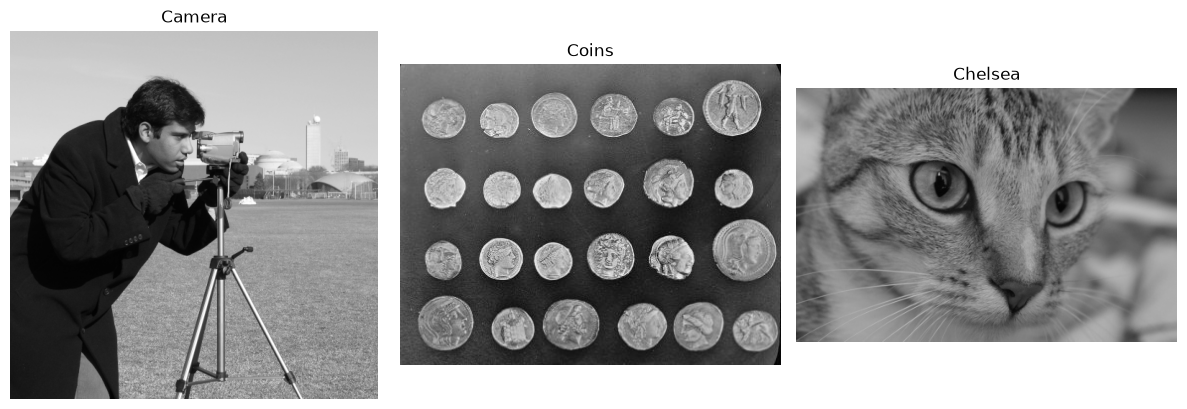

In [3]:
plt.figure(figsize=(16, 4))

for i, (name, img) in enumerate(images.items()):
    plt.subplot(1, 4, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Create the 2D convolution function

The function below follows the lab instructions:

1. It checks that the kernel has odd dimensions.
2. It flips the kernel in both directions. This makes it true convolution.
3. It uses NumPy reflect padding.
4. It calculates each pixel using nested loops and float64 values.
5. It returns an array with the same height and width as the input image.

The function returns float64. We convert filtered images to uint8 only after filtering.

In [4]:
def conv2d_loop(img, kernel):
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if kernel.ndim != 2:
        raise ValueError("Kernel must be a 2D array.")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    # Flip the kernel for true convolution.
    kernel = np.flip(kernel, axis=(0, 1))

    pad_h = kh // 2
    pad_w = kw // 2

    # Reflect padding keeps the output size the same.
    padded_img = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="reflect"
    )

    output = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            total = 0.0

            for m in range(kh):
                for n in range(kw):
                    total = total + padded_img[i + m, j + n] * kernel[m, n]

            output[i, j] = total

    return output


def to_uint8(img):
    return np.clip(np.round(img), 0, 255).astype(np.uint8)


print("Convolution function is ready.")

Convolution function is ready.


## 5. Verify our convolution with OpenCV

We use a 3×3 mean kernel and the Camera image. OpenCV's `filter2D` uses `BORDER_REFLECT_101`, which matches NumPy's `mode="reflect"` border behaviour.

The largest absolute difference is printed. A very small difference is expected because of floating-point calculation.

In [5]:
mean_kernel_3 = np.ones((3, 3), dtype=np.float64) / 9

our_result = conv2d_loop(camera, mean_kernel_3)
opencv_result = cv2.filter2D(
    camera.astype(np.float64),
    -1,
    mean_kernel_3,
    borderType=cv2.BORDER_REFLECT_101
)

largest_difference = np.max(np.abs(our_result - opencv_result))

print("Largest absolute difference:", largest_difference)
print("Our result shape:", our_result.shape)
print("OpenCV result shape:", opencv_result.shape)
print("Our result data type:", our_result.dtype)

Largest absolute difference: 0.0
Our result shape: (512, 512)
OpenCV result shape: (512, 512)
Our result data type: float64


## 6. Generate noise using seed = 5

Both functions use a fixed seed. This means that running them again with the same image and parameters produces the same noisy image.

- Gaussian noise adds random normal values to pixels.
- Salt-and-pepper noise changes a selected number of pixels to black (0) or white (255).

In [6]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, img.shape)
    noisy_img = img.astype(np.float64) + noise
    return to_uint8(noisy_img)


def add_salt_pepper(img, amount=0.05, seed=5):
    if amount < 0 or amount > 1:
        raise ValueError("Amount must be between 0 and 1.")

    rng = np.random.default_rng(seed)
    noisy_img = img.copy()

    total_pixels = img.size
    number_of_noisy_pixels = int(amount * total_pixels)
    number_of_salt = number_of_noisy_pixels // 2
    number_of_pepper = number_of_noisy_pixels - number_of_salt

    flat_img = noisy_img.reshape(-1)
    positions = rng.choice(total_pixels, number_of_noisy_pixels, replace=False)

    salt_positions = positions[:number_of_salt]
    pepper_positions = positions[number_of_salt:]

    flat_img[salt_positions] = 255
    flat_img[pepper_positions] = 0

    return noisy_img


gaussian_noisy = {}
salt_pepper_noisy = {}

for name, img in images.items():
    gaussian_noisy[name] = add_gaussian_noise(img, sigma=20, seed=5)
    salt_pepper_noisy[name] = add_salt_pepper(img, amount=0.05, seed=5)

print("Both types of noise have been created.")

Both types of noise have been created.


## 7. Check that the noise is reproducible

We generate the noise again with seed 5 and compare it with the first result using `np.array_equal`. The result should be `True`.

In [7]:
for name, img in images.items():
    gaussian_again = add_gaussian_noise(img, sigma=20, seed=5)
    salt_pepper_again = add_salt_pepper(img, amount=0.05, seed=5)

    print(name)
    print("Gaussian noise identical:", np.array_equal(gaussian_noisy[name], gaussian_again))
    print("Salt-and-pepper noise identical:", np.array_equal(salt_pepper_noisy[name], salt_pepper_again))

Camera
Gaussian noise identical: True
Salt-and-pepper noise identical: True
Coins
Gaussian noise identical: True
Salt-and-pepper noise identical: True
Chelsea
Gaussian noise identical: True
Salt-and-pepper noise identical: True


## 8. Compare original images and noisy images

The following grid shows each clean original beside its Gaussian-noise and salt-and-pepper versions.

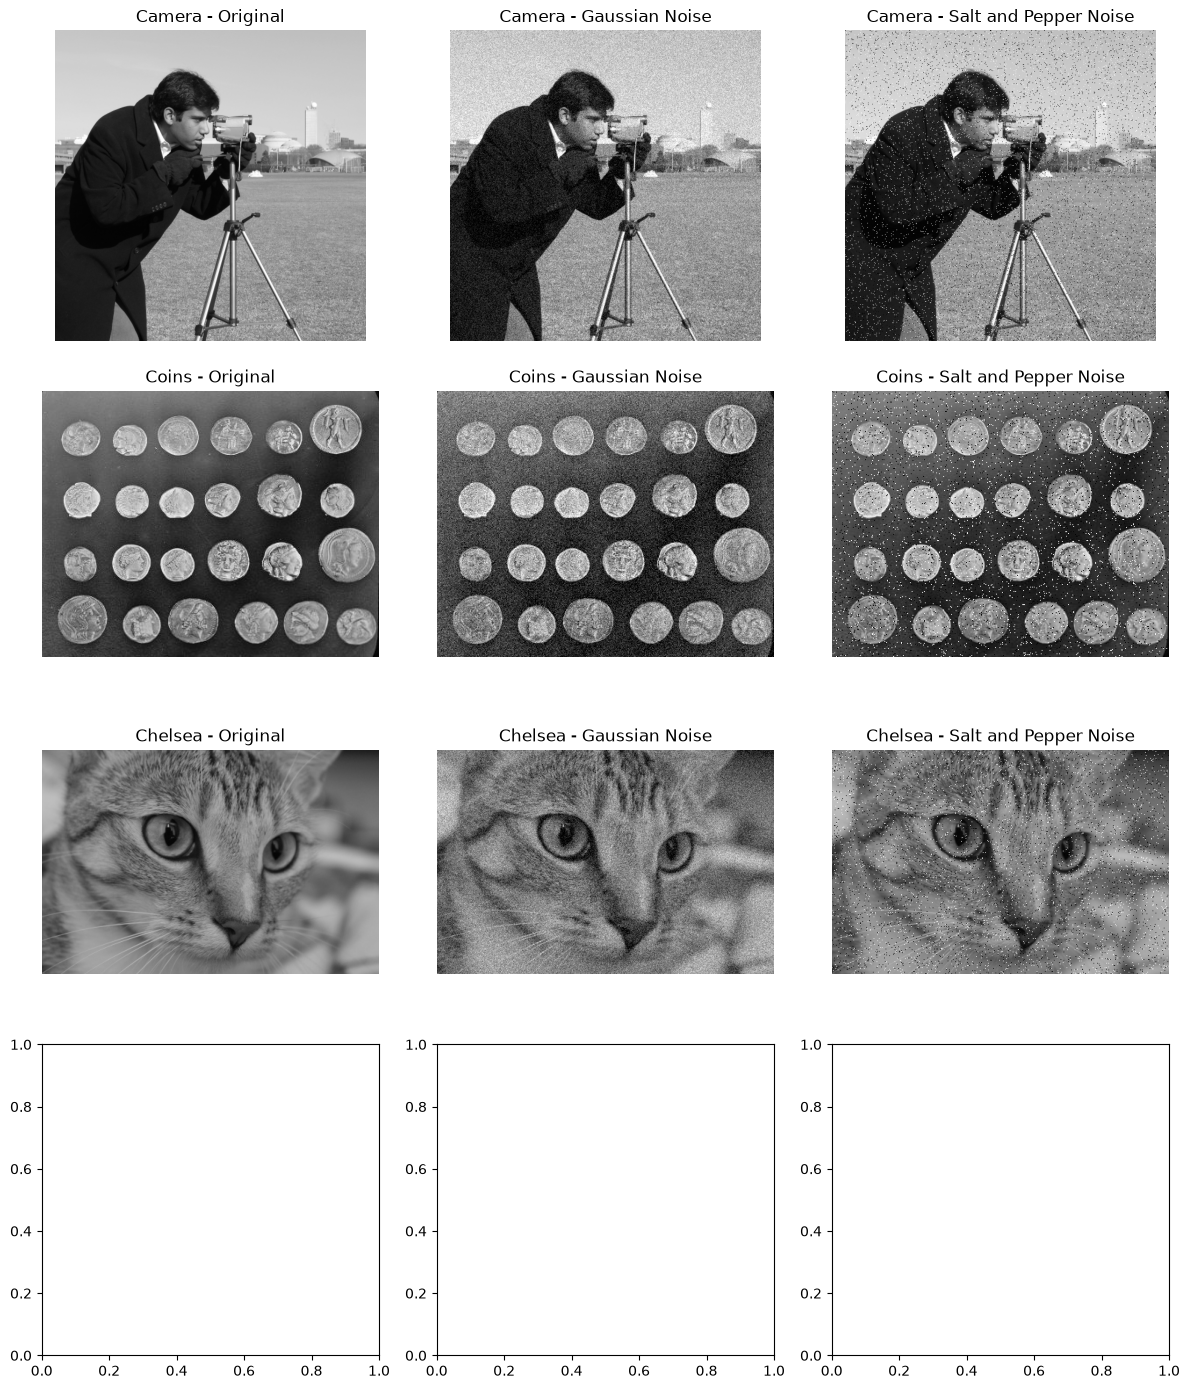

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row, (name, img) in enumerate(images.items()):
    axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(name + " - Original")

    axes[row, 1].imshow(gaussian_noisy[name], cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(name + " - Gaussian Noise")

    axes[row, 2].imshow(salt_pepper_noisy[name], cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title(name + " - Salt and Pepper Noise")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 9. Create mean and Gaussian kernels

A smoothing kernel must have weights that add up to 1. We use:

- Mean kernel: all values are equal.
- Gaussian kernel: a normalized 2D kernel made from binomial weights. The 3×3 kernel is the required 1-2-1 kernel divided by 16.

The 5×5 and 7×7 Gaussian kernels are made in the same way and are also normalized to sum to 1.

In [9]:
def make_mean_kernel(size):
    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    kernel = np.ones((size, size), dtype=np.float64)
    kernel = kernel / (size * size)
    return kernel


def make_gaussian_kernel(size):
    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    if size == 3:
        values = np.array([1, 2, 1], dtype=np.float64)
    elif size == 5:
        values = np.array([1, 4, 6, 4, 1], dtype=np.float64)
    else:
        values = np.array([1, 6, 15, 20, 15, 6, 1], dtype=np.float64)

    kernel = np.outer(values, values)
    kernel = kernel / np.sum(kernel)
    return kernel


for size in [3, 5, 7]:
    mean_kernel = make_mean_kernel(size)
    gaussian_kernel = make_gaussian_kernel(size)

    print("Kernel size:", size)
    print("Mean kernel weight sum:", np.sum(mean_kernel))
    print("Gaussian kernel weight sum:", np.sum(gaussian_kernel))

Kernel size: 3
Mean kernel weight sum: 1.0
Gaussian kernel weight sum: 1.0
Kernel size: 5
Mean kernel weight sum: 1.0
Gaussian kernel weight sum: 1.0
Kernel size: 7
Mean kernel weight sum: 0.9999999999999999
Gaussian kernel weight sum: 1.0


## 10. Apply the three filters

For each noisy image, we apply:

- Mean filter using our convolution function.
- Gaussian filter using OpenCV's `GaussianBlur`.
- Median filter using OpenCV's `medianBlur`.

All filters use a 3×3 kernel in this section. We compare each filtered result with the clean original image.

In [10]:
def apply_filters(noisy_img, size=3):
    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    mean_kernel = make_mean_kernel(size)

    # Mean filter using our own convolution.
    mean_result = to_uint8(conv2d_loop(noisy_img, mean_kernel))

    # Gaussian filter using OpenCV.
    gaussian_result = cv2.GaussianBlur(
        noisy_img, (size, size), 0,
        borderType=cv2.BORDER_REFLECT_101
    )

    # Median filter using OpenCV.
    median_result = cv2.medianBlur(noisy_img, size)

    return mean_result, gaussian_result, median_result


filtered_results = {}

for name in images:
    filtered_results[(name, "Gaussian Noise")] = apply_filters(gaussian_noisy[name], 3)
    filtered_results[(name, "Salt and Pepper Noise")] = apply_filters(salt_pepper_noisy[name], 3)

print("Filtering completed for all six noisy images.")

Filtering completed for all six noisy images.


## 11. Display the 3×3 filter results for every noisy image

Each figure shows the clean original, the noisy image, and the three filtered results. This makes it possible to judge the filters against the clean original, as required by rule R6.

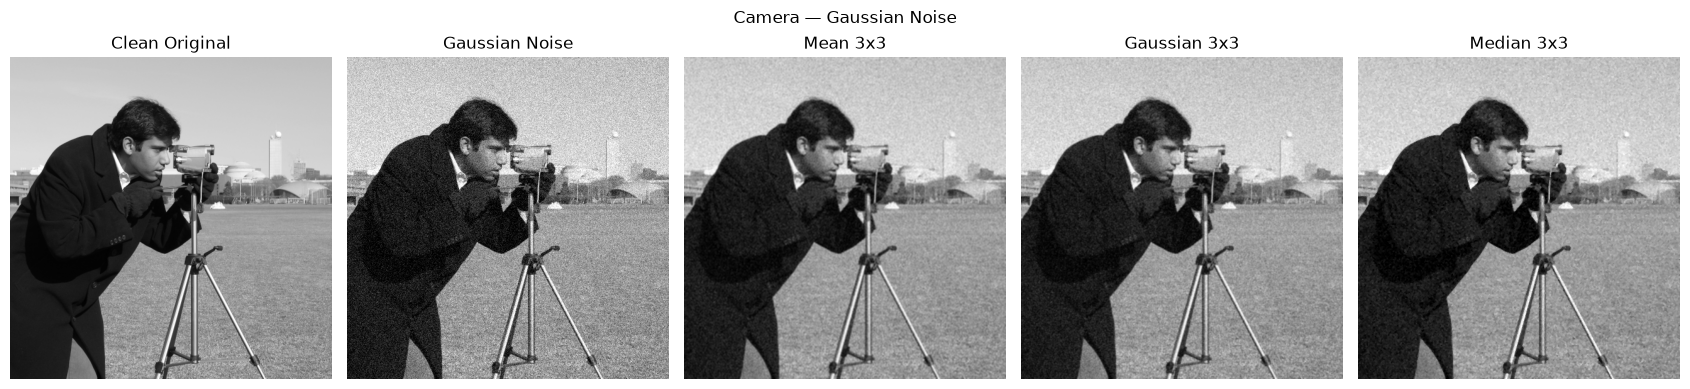

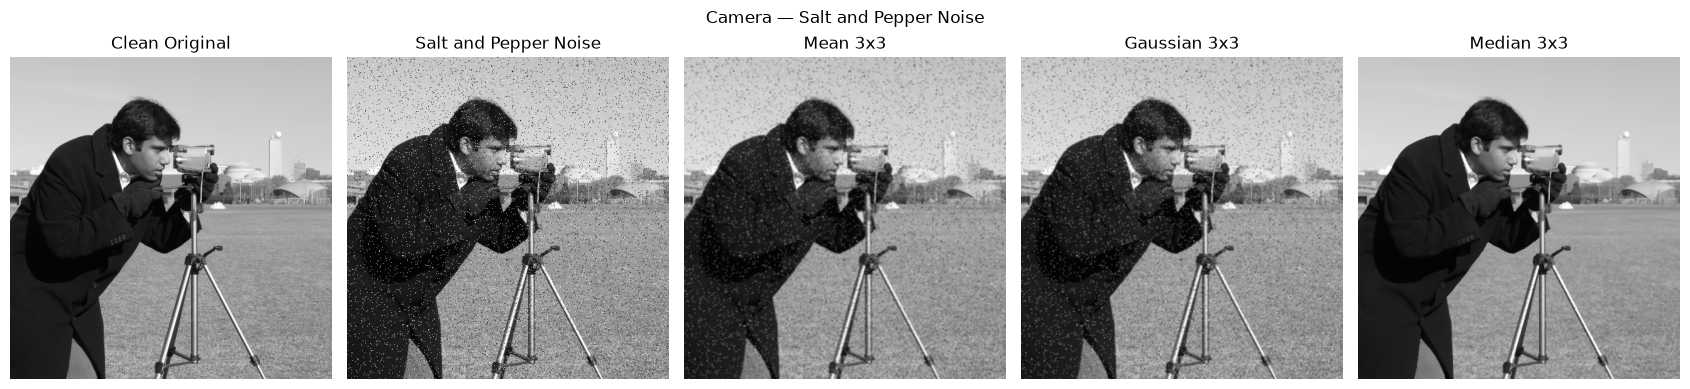

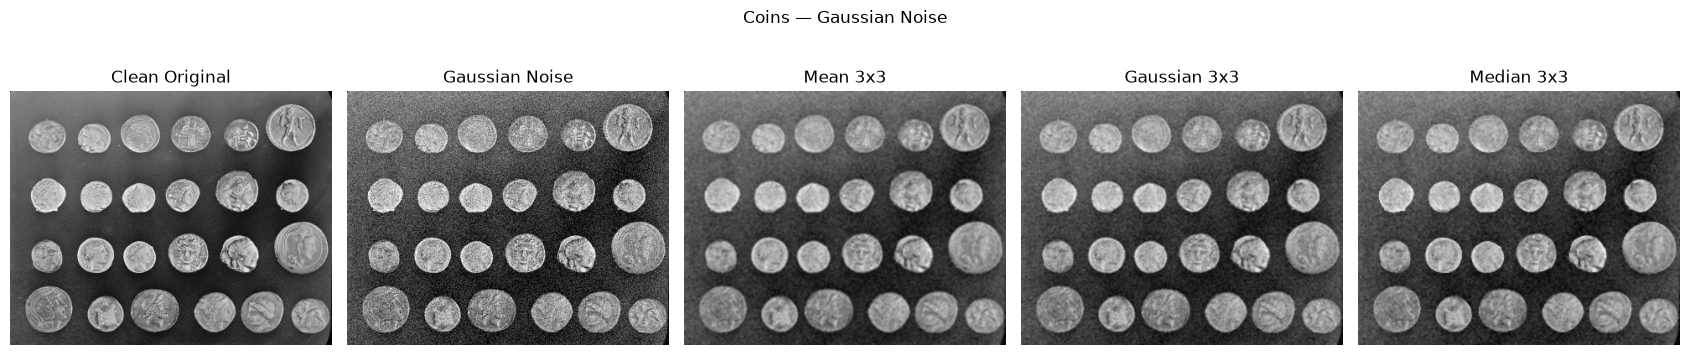

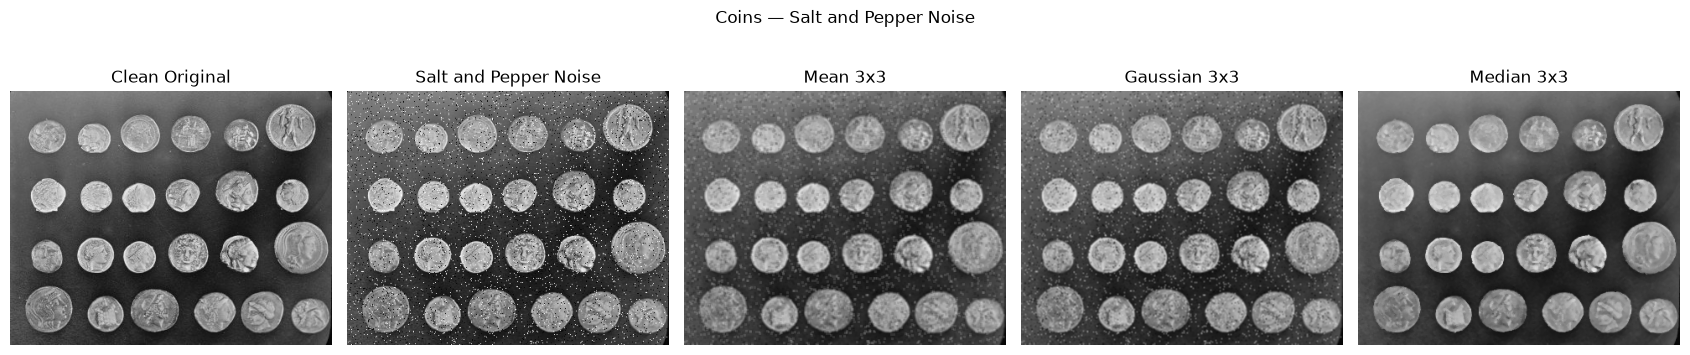

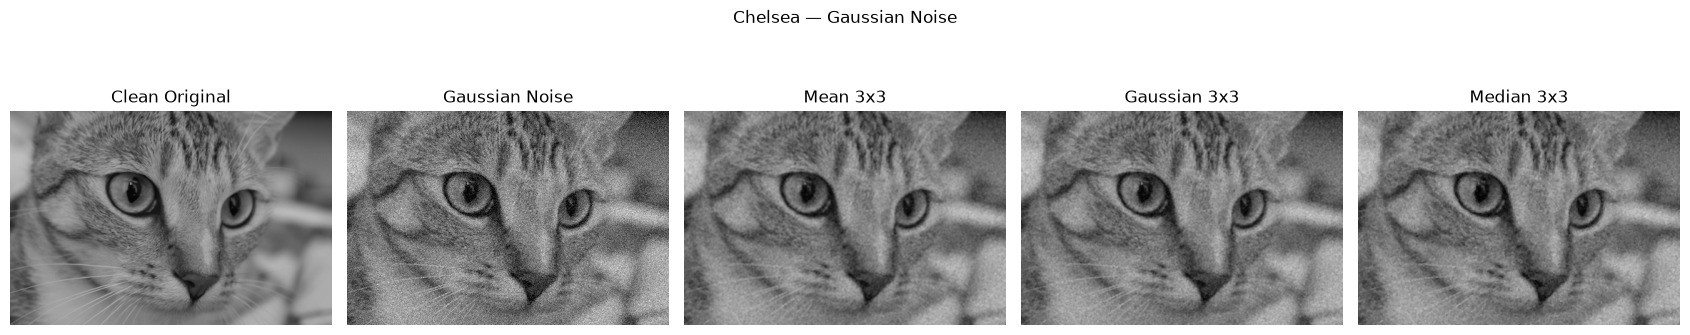

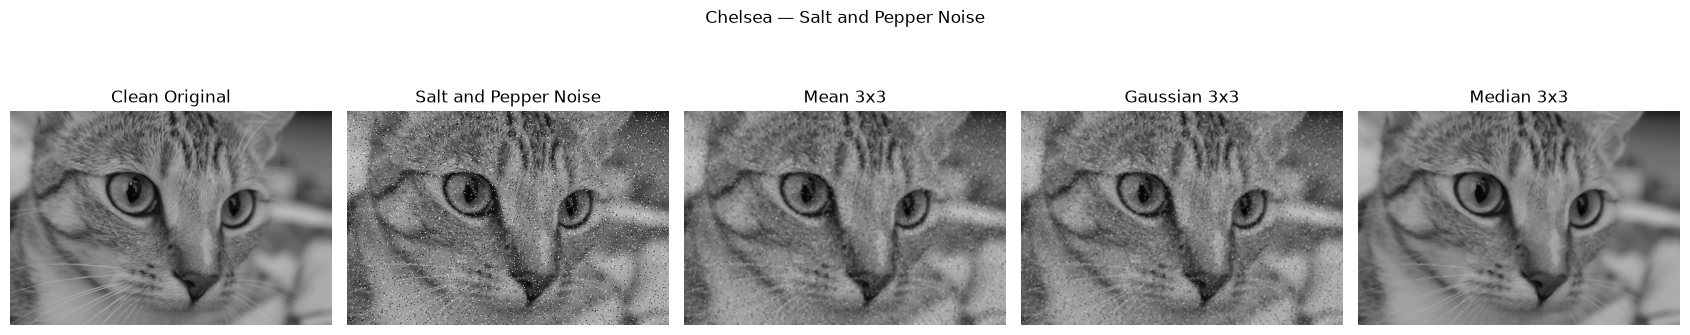

In [11]:
for name, original in images.items():
    for noise_name, noisy_img in [
        ("Gaussian Noise", gaussian_noisy[name]),
        ("Salt and Pepper Noise", salt_pepper_noisy[name])
    ]:
        mean_result, gaussian_result, median_result = filtered_results[(name, noise_name)]

        fig, axes = plt.subplots(1, 5, figsize=(17, 4))
        display_images = [
            (original, "Clean Original"),
            (noisy_img, noise_name),
            (mean_result, "Mean 3x3"),
            (gaussian_result, "Gaussian 3x3"),
            (median_result, "Median 3x3")
        ]

        for ax, (img, title) in zip(axes, display_images):
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
            ax.set_title(title)
            ax.axis("off")

        fig.suptitle(name + " — " + noise_name)
        plt.tight_layout()
        plt.show()

## 12. Compare kernel sizes on the noisiest image

To select the noisiest test case, we calculate mean squared error (MSE) between each noisy image and its clean original. The case with the highest MSE is selected.

Then we display a 3×3 grid: rows are the three filters and columns are kernel sizes 3×3, 5×5 and 7×7.

In [12]:
noise_cases = []

for name, original in images.items():
    for noise_name, noisy_img in [
        ("Gaussian Noise", gaussian_noisy[name]),
        ("Salt and Pepper Noise", salt_pepper_noisy[name])
    ]:
        mse = np.mean((original.astype(np.float64) - noisy_img.astype(np.float64)) ** 2)
        noise_cases.append((mse, name, noise_name, noisy_img))

noise_cases.sort(key=lambda item: item[0], reverse=True)

highest_mse, selected_name, selected_noise_name, selected_noisy = noise_cases[0]

print("Selected noisiest image:", selected_name)
print("Noise type:", selected_noise_name)
print("MSE compared with clean original:", highest_mse)

Selected noisiest image: Camera
Noise type: Salt and Pepper Noise
MSE compared with clean original: 1089.9780235290527


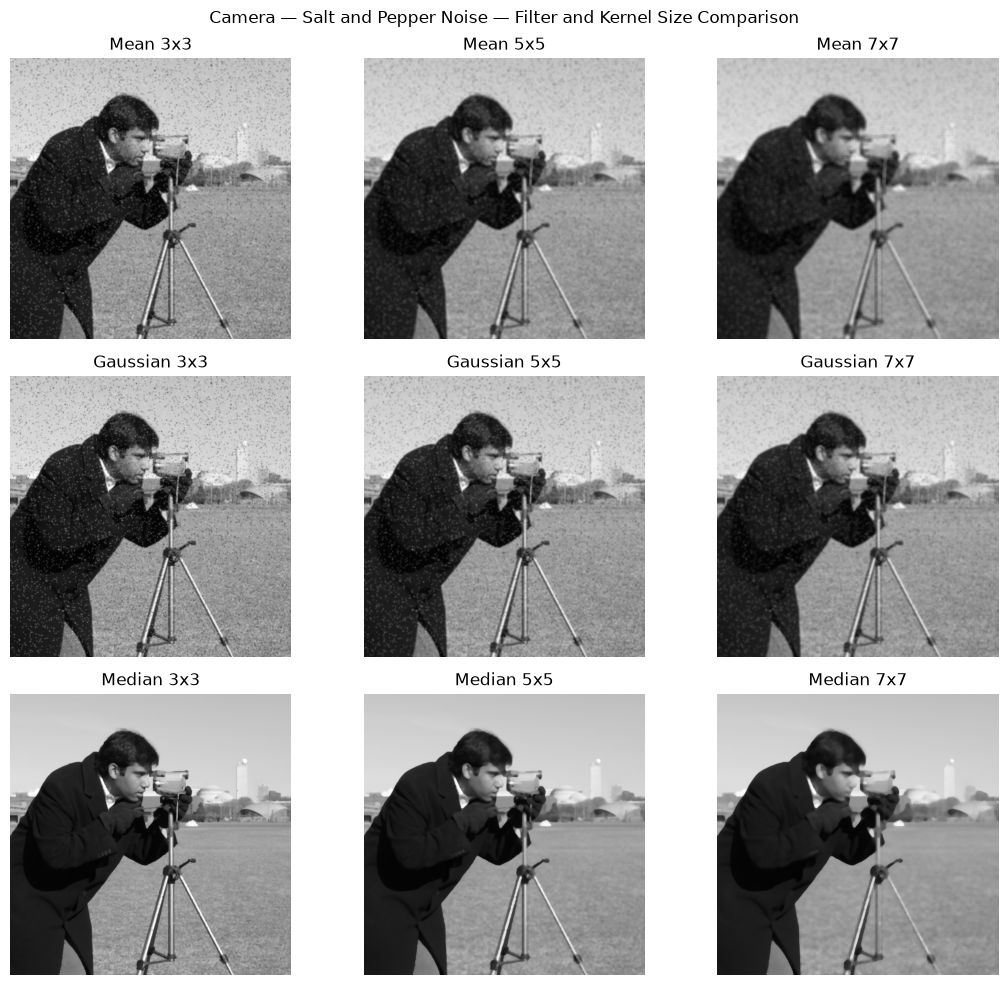

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
filter_names = ["Mean", "Gaussian", "Median"]
kernel_sizes = [3, 5, 7]

for col, size in enumerate(kernel_sizes):
    mean_result, gaussian_result, median_result = apply_filters(selected_noisy, size)

    results = [mean_result, gaussian_result, median_result]

    for row in range(3):
        axes[row, col].imshow(results[row], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(filter_names[row] + " " + str(size) + "x" + str(size))
        axes[row, col].axis("off")

plt.suptitle(selected_name + " — " + selected_noise_name + " — Filter and Kernel Size Comparison")
plt.tight_layout()
plt.show()

## 13. Check the filtering rules (R1–R4)

We check that filtered images:

- Have the same shape as their input.
- Have `uint8` data type.
- Have values between 0 and 255.
- Use odd kernel sizes.
- Use smoothing kernels whose weights add up to 1.

In [14]:
all_checks_passed = True

for name, original in images.items():
    for noise_name, noisy_img in [
        ("Gaussian Noise", gaussian_noisy[name]),
        ("Salt and Pepper Noise", salt_pepper_noisy[name])
    ]:
        for size in [3, 5, 7]:
            mean_result, gaussian_result, median_result = apply_filters(noisy_img, size)

            for filter_name, result in [
                ("Mean", mean_result),
                ("Gaussian", gaussian_result),
                ("Median", median_result)
            ]:
                shape_ok = result.shape == noisy_img.shape
                dtype_ok = result.dtype == np.uint8
                range_ok = result.min() >= 0 and result.max() <= 255

                print(name, noise_name, filter_name, size,
                      "| shape:", shape_ok,
                      "| uint8:", dtype_ok,
                      "| range:", range_ok)

                if not (shape_ok and dtype_ok and range_ok):
                    all_checks_passed = False

print("All output checks passed:", all_checks_passed)

Camera Gaussian Noise Mean 3 | shape: True | uint8: True | range: True
Camera Gaussian Noise Gaussian 3 | shape: True | uint8: True | range: True
Camera Gaussian Noise Median 3 | shape: True | uint8: True | range: True
Camera Gaussian Noise Mean 5 | shape: True | uint8: True | range: True
Camera Gaussian Noise Gaussian 5 | shape: True | uint8: True | range: True
Camera Gaussian Noise Median 5 | shape: True | uint8: True | range: True
Camera Gaussian Noise Mean 7 | shape: True | uint8: True | range: True
Camera Gaussian Noise Gaussian 7 | shape: True | uint8: True | range: True
Camera Gaussian Noise Median 7 | shape: True | uint8: True | range: True
Camera Salt and Pepper Noise Mean 3 | shape: True | uint8: True | range: True
Camera Salt and Pepper Noise Gaussian 3 | shape: True | uint8: True | range: True
Camera Salt and Pepper Noise Median 3 | shape: True | uint8: True | range: True
Camera Salt and Pepper Noise Mean 5 | shape: True | uint8: True | range: True
Camera Salt and Pepper No

### Check that even kernel sizes are rejected

The lab requires odd kernel sizes. We deliberately try an even median kernel size of 4 and catch the error.

In [15]:
try:
    cv2.medianBlur(camera, 4)
except cv2.error as error:
    print("Even kernel size 4 was rejected by OpenCV.")
    print("Error type:", type(error).__name__)

Even kernel size 4 was rejected by OpenCV.
Error type: error


## 14. Dry-run Exercise 1 — Spike response

Given neighbourhood:

\[
\begin{bmatrix}
40 & 40 & 40 \\
40 & 255 & 40 \\
40 & 40 & 40
\end{bmatrix}
\]

### Mean filter

There are eight values of 40 and one value of 255.

Sum = (8 × 40) + 255 = 575

Mean output = 575 ÷ 9 = **63.8889**

### Gaussian filter

The 3×3 Gaussian kernel is:

\[
\frac{1}{16}
\begin{bmatrix}
1 & 2 & 1 \\
2 & 4 & 2 \\
1 & 2 & 1
\end{bmatrix}
\]

The centre pixel has weight 4. The sum of the other weights is 12.

Weighted sum = (255 × 4) + (40 × 12) = 1020 + 480 = 1500

Gaussian output = 1500 ÷ 16 = **93.75**

### Median filter

Sorted values are eight 40s and one 255. The middle (fifth) value is **40**.

In [16]:
spike = np.array([
    [40, 40, 40],
    [40, 255, 40],
    [40, 40, 40]
], dtype=np.uint8)

mean_spike = np.sum(spike) / 9

spike_gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16

gaussian_spike = np.sum(spike.astype(np.float64) * spike_gaussian_kernel)
median_spike = np.median(spike)

print("Mean centre output:", mean_spike)
print("Gaussian centre output:", gaussian_spike)
print("Median centre output:", median_spike)

Mean centre output: 63.888888888888886
Gaussian centre output: 93.75
Median centre output: 40.0


## 15. Dry-run Exercise 2 — Reflect padding at a corner

Given image:

\[
\begin{bmatrix}
10 & 20 & 30 \\
40 & 50 & 60 \\
70 & 80 & 90
\end{bmatrix}
\]

Using NumPy `mode="reflect"`, the 3×3 neighbourhood around the top-left pixel (0, 0) is:

\[
\begin{bmatrix}
50 & 40 & 50 \\
20 & 10 & 20 \\
50 & 40 & 50
\end{bmatrix}
\]

Sum = 50 + 40 + 50 + 20 + 10 + 20 + 50 + 40 + 50 = 330

Mean output = 330 ÷ 9 = **36.6667**

In [17]:
small_image = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float64)

padded_small_image = np.pad(small_image, ((1, 1), (1, 1)), mode="reflect")
corner_neighbourhood = padded_small_image[0:3, 0:3]
corner_mean = np.mean(corner_neighbourhood)

print("Padded 3x3 neighbourhood at top-left:")
print(corner_neighbourhood)
print("Mean output at (0, 0):", corner_mean)

Padded 3x3 neighbourhood at top-left:
[[50. 40. 50.]
 [20. 10. 20.]
 [50. 40. 50.]]
Mean output at (0, 0): 36.666666666666664


## 16. Observations from the figures

**1. Which filter looks best on Gaussian noise, and which looks worst?**  
In the Gaussian-noise comparison figures, the Gaussian filter generally gives the smoothest result while keeping a more natural appearance. The mean filter can look more blurred because it gives equal importance to every pixel. Check the Camera and Coins figures and compare the filtered areas with their clean originals.

**2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**  
The median filter generally looks best for salt-and-pepper noise. In the salt-and-pepper comparison figures, isolated black and white dots are removed by the median filter. Mean and Gaussian filters average the extreme values with nearby pixels, so the dots can spread into their surroundings and blur the image.

**3. How do mean and Gaussian filters compare on a sharp edge?**  
Look at the boundary between a dark and a bright area in the Camera or Coins comparison. Both filters smooth the edge. The Gaussian filter gives more weight to nearby pixels, while the mean filter gives equal weight to all pixels in its window.

**4. What happens to fine detail at 7×7?**  
In the 7×7 column of the kernel-size grid, small details and thin edges become less clear because a larger neighbourhood is used for smoothing. This is especially noticeable in small features and texture.

**5. Why must the kernel size be odd?**  
An odd-sized kernel has one centre pixel, so the filter window can be placed around the pixel being calculated. An even-sized kernel does not have one exact centre pixel. The notebook also demonstrates that an even median kernel size is rejected.

> These are general observations to guide the comparison. Before submitting, check the displayed grids and adjust any wording that does not match what you can actually see in your own notebook outputs.

## 17. Viva preparation — two questions

**Q1. What is a kernel?**  
A kernel is a small matrix of numbers used to process an image. It moves over the image and helps calculate new pixel values.

**Q2. Which filter would you use for salt-and-pepper noise, and why?**  
I would use the median filter because it replaces a pixel with the middle value of its neighbourhood. It removes very bright and very dark dots without averaging them into nearby pixels.

## 18. Final conclusion

In this lab, I implemented 2D convolution using nested loops and reflect padding. I generated Gaussian and salt-and-pepper noise using a fixed seed and applied mean, Gaussian and median filters. I compared the filtered images with the clean originals and checked the output size, data type, pixel range and kernel weight sums.

The median filter was useful for removing salt-and-pepper noise, while the Gaussian filter was useful for smoothing Gaussian noise. Larger kernels removed more noise but also removed more fine detail.